# Lab Assignment 8 - UCS420 Cognitive Computing
**NLP using Python-II** (Feature extraction from text, sentiment analysis and text generation)

**Name-Tanishq**

**Roll No-1024170156**

**Batch-3Q21**

In [ ]:
!pip install -q nltk scikit-learn pandas matplotlib textblob wordcloud tensorflow

## Setup: imports, NLTK data and the shared paragraph

In [2]:
import re
import numpy as np
import matplotlib.pyplot as plt
import nltk

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import FreqDist

stop_words = set(stopwords.words("english"))

# Favourite topic: street food
paragraph = (
    "Street food is the most exciting part of Indian culture because every city has its own special flavours. "
    "In the evening, crowded stalls serve hot samosas, crispy chaat, and spicy golgappe to hungry people. "
    "I love the smell of fresh jalebi frying in sweet syrup near the busy market. "
    "Vendors prepare each dish in front of customers, which makes the experience fun and trustworthy. "
    "Eating with friends at a roadside stall costs very little but creates memories that last for years. "
    "Street food proves that simple ingredients cooked with passion can taste better than any expensive restaurant meal."
)

## Q1. Text preprocessing (re, tokenization, stopwords, frequency distribution)

Q1. TEXT PREPROCESSING
1) Cleaned text:
 street food is the most exciting part of indian culture because every city has its own special flavours in the evening crowded stalls serve hot samosas crispy chaat and spicy golgappe to hungry people i love the smell of fresh jalebi frying in sweet syrup near the busy market vendors prepare each dish in front of customers which makes the experience fun and trustworthy eating with friends at a roadside stall costs very little but creates memories that last for years street food proves that simple ingredients cooked with passion can taste better than any expensive restaurant meal 

2) Sentences:
   1. Street food is the most exciting part of Indian culture because every city has its own special flavours.
   2. In the evening, crowded stalls serve hot samosas, crispy chaat, and spicy golgappe to hungry people.
   3. I love the smell of fresh jalebi frying in sweet syrup near the busy market.
   4. Vendors prepare each dish in front of customers, w

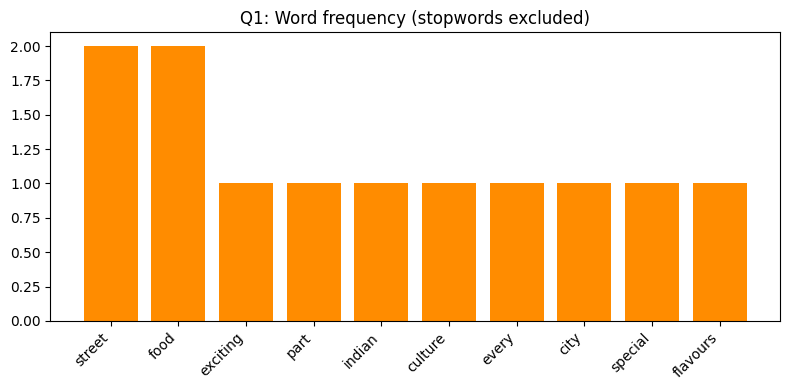

In [3]:
print("=" * 70, "\nQ1. TEXT PREPROCESSING\n", "=" * 70, sep="")
# 1. lowercase + remove punctuation
clean = re.sub(r"[^\w\s]", "", paragraph.lower())
print("1) Cleaned text:\n", clean, "\n")

# 2. tokenize into sentences and words
sentences = sent_tokenize(paragraph)
print("2) Sentences:")
for i, s in enumerate(sentences, 1):
    print(f"   {i}. {s}")
words = word_tokenize(clean)
print("   Words:", words, "\n")

# 3. split() vs word_tokenize()
sample = "I can't wait for the monsoon, it's my favourite season!"
print("3) split() vs word_tokenize() on:", repr(sample))
print("   split()        :", sample.split())
print("   word_tokenize():", word_tokenize(sample))
print("   -> split() only cuts on whitespace, so punctuation stays glued to words\n"
      "      ('monsoon,', 'season!') and contractions stay whole. word_tokenize()\n"
      "      separates punctuation as its own token and splits contractions\n"
      "      (ca + n't, it + 's).\n")

# 4. stopword removal
filtered = [w for w in words if w not in stop_words]
print("4) After stopword removal:", filtered, "\n")

# 5. frequency distribution
fd = FreqDist(filtered)
print("5) Most common words:", fd.most_common(10))
top = fd.most_common(10)
plt.figure(figsize=(8, 4))
plt.bar([w for w, _ in top], [c for _, c in top], color="darkorange")
plt.xticks(rotation=45, ha="right")
plt.title("Q1: Word frequency (stopwords excluded)")
plt.tight_layout()
plt.savefig("q1_word_freq.png", dpi=120)
plt.show()

## Q2. Regex, stemming and lemmatization

In [4]:
print("\n" + "=" * 70, "\nQ2. REGEX, STEMMING, LEMMATIZATION\n", "=" * 70, sep="")
alpha_words = re.findall(r"[A-Za-z]+", paragraph.lower())
print("1) Alphabet-only words:", alpha_words, "\n")
no_stop = [w for w in alpha_words if w not in stop_words]
print("2) Without stopwords:", no_stop, "\n")

ps = PorterStemmer()
stemmed = [ps.stem(w) for w in no_stop]
print("3) Stemmed:", stemmed, "\n")

wl = WordNetLemmatizer()
lemmatized = [wl.lemmatize(w) for w in no_stop]                 # default noun
lemmatized_v = [wl.lemmatize(w, pos="v") for w in no_stop]      # verb
print("4) Lemmatized (noun):", lemmatized)
print("   Lemmatized (verb):", lemmatized_v, "\n")

print("5) Comparison (only words where outputs differ):")
print(f"   {'Original':<15}{'Stem':<15}{'Lemma(n)':<15}{'Lemma(v)':<15}")
for o, s, l, lv in zip(no_stop, stemmed, lemmatized, lemmatized_v):
    if len({o, s, l, lv}) > 1:
        print(f"   {o:<15}{s:<15}{l:<15}{lv:<15}")
print("""
   Explanation:
   * Stemming chops suffixes using fixed rules, so it is fast but can produce
     non-words (e.g. 'studies' -> 'studi', 'happiness' -> 'happi').
   * Lemmatization uses a dictionary (WordNet) and the part of speech, so it
     returns real words (e.g. 'stalls' -> 'stall', 'cooked' -> 'cook' as a verb)
     but it is slower and needs the POS tag for the best result.
   * Prefer STEMMING for speed on large corpora where readability does not
     matter (search engines, information retrieval, text classification).
   * Prefer LEMMATIZATION when meaningful words matter (chatbots, sentiment
     analysis, topic modelling, question answering, any output shown to humans).
""")


Q2. REGEX, STEMMING, LEMMATIZATION
1) Alphabet-only words: ['street', 'food', 'is', 'the', 'most', 'exciting', 'part', 'of', 'indian', 'culture', 'because', 'every', 'city', 'has', 'its', 'own', 'special', 'flavours', 'in', 'the', 'evening', 'crowded', 'stalls', 'serve', 'hot', 'samosas', 'crispy', 'chaat', 'and', 'spicy', 'golgappe', 'to', 'hungry', 'people', 'i', 'love', 'the', 'smell', 'of', 'fresh', 'jalebi', 'frying', 'in', 'sweet', 'syrup', 'near', 'the', 'busy', 'market', 'vendors', 'prepare', 'each', 'dish', 'in', 'front', 'of', 'customers', 'which', 'makes', 'the', 'experience', 'fun', 'and', 'trustworthy', 'eating', 'with', 'friends', 'at', 'a', 'roadside', 'stall', 'costs', 'very', 'little', 'but', 'creates', 'memories', 'that', 'last', 'for', 'years', 'street', 'food', 'proves', 'that', 'simple', 'ingredients', 'cooked', 'with', 'passion', 'can', 'taste', 'better', 'than', 'any', 'expensive', 'restaurant', 'meal'] 

2) Without stopwords: ['street', 'food', 'exciting', 'par

## Q3. Bag of Words and TF-IDF

In [5]:
print("=" * 70, "\nQ3. BoW AND TF-IDF\n", "=" * 70, sep="")
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "The electric scooter has a strong battery and the scooter charges fast, so the battery lasts long for daily city rides",
    "Heavy rain floods the city roads and the rain delays trains, so daily travel in the city becomes difficult",
    "The mystery novel has a clever plot and the plot keeps readers hooked, so the novel feels fresh and exciting",
]
cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(texts)
print("1) Bag of Words matrix:")
print(pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(),
                   index=["Text1", "Text2", "Text3"]).T.to_string(), "\n")

tv = TfidfVectorizer(stop_words="english")
tfidf = tv.fit_transform(texts)
feat = tv.get_feature_names_out()
print("2) TF-IDF matrix (rounded):")
print(pd.DataFrame(tfidf.toarray().round(3), columns=feat,
                   index=["Text1", "Text2", "Text3"]).T.to_string(), "\n")

print("3) Top 3 TF-IDF keywords per text:")
for i, t in enumerate(texts):
    row = tfidf[i].toarray().ravel()
    idx = row.argsort()[::-1][:3]
    print(f"   Text{i+1}: ", [(feat[j], round(row[j], 3)) for j in idx])
print("""
   Interpretation: TF-IDF gives a high score to a word that is frequent inside
   one text but rare across the other texts. Words repeated within a text get a
   higher term frequency, so they rise to the top of that text's keywords.
   Words shared by several texts (such as 'city' or 'daily') receive a lower
   inverse document frequency, so they are weighted down compared with words
   that belong to only one text. Raw Bag of Words counts treat every
   occurrence equally and cannot make this distinction.
""")

Q3. BoW AND TF-IDF
1) Bag of Words matrix:
           Text1  Text2  Text3
battery        2      0      0
charges        1      0      0
city           1      2      0
clever         0      0      1
daily          1      1      0
delays         0      1      0
difficult      0      1      0
electric       1      0      0
exciting       0      0      1
fast           1      0      0
feels          0      0      1
floods         0      1      0
fresh          0      0      1
heavy          0      1      0
hooked         0      0      1
keeps          0      0      1
lasts          1      0      0
long           1      0      0
mystery        0      0      1
novel          0      0      2
plot           0      0      2
rain           0      2      0
readers        0      0      1
rides          1      0      0
roads          0      1      0
scooter        2      0      0
strong         1      0      0
trains         0      1      0
travel         0      1      0 

2) TF-IDF matrix (rounded

## Q4. Jaccard and cosine similarity

In [6]:
print("=" * 70, "\nQ4. JACCARD AND COSINE SIMILARITY\n", "=" * 70, sep="")
from sklearn.metrics.pairwise import cosine_similarity

t_cloud = ("Cloud computing lets users store data and run applications on remote servers over the internet. "
           "Companies pay only for the storage and computing power they actually use. "
           "It makes software easy to scale and update from any location. "
           "Popular uses include online backup, streaming services and web hosting.")
t_iot = ("The Internet of Things connects everyday devices such as sensors, watches and appliances to the internet. "
         "These devices collect data and share it with other devices automatically. "
         "It is used in smart homes, farming and health monitoring. "
         "It helps people control and track things remotely.")

def preprocess(t):
    toks = word_tokenize(re.sub(r"[^\w\s]", "", t.lower()))
    return [wl.lemmatize(w) for w in toks if w not in stop_words]

p1, p2 = preprocess(t_cloud), preprocess(t_iot)
print("1) Tokens (Cloud Computing):", p1)
print("   Tokens (IoT)            :", p2, "\n")

s1, s2 = set(p1), set(p2)
jaccard = len(s1 & s2) / len(s1 | s2)
print("2a) Common words:", s1 & s2)
print(f"    Jaccard similarity = {len(s1 & s2)}/{len(s1 | s2)} = {jaccard:.4f}")

tf = TfidfVectorizer(stop_words="english")
m = tf.fit_transform([t_cloud, t_iot])
cos = cosine_similarity(m[0], m[1])[0][0]
print(f"2b) Cosine similarity (TF-IDF) = {cos:.4f}")
print("""
2c) Analysis:
    Jaccard only checks which words are shared (set overlap) and ignores how
    often a word occurs or how important it is. Cosine similarity on TF-IDF
    vectors weights words by frequency and importance, so common shared words
    count for less than topic-defining words. Both scores are low when the
    texts describe different technologies, but cosine similarity gives better
    insight because it respects word frequency and handles texts of different
    lengths; Jaccard is a quick, simple measure of vocabulary overlap.
""")

Q4. JACCARD AND COSINE SIMILARITY
1) Tokens (Cloud Computing): ['cloud', 'computing', 'let', 'user', 'store', 'data', 'run', 'application', 'remote', 'server', 'internet', 'company', 'pay', 'storage', 'computing', 'power', 'actually', 'use', 'make', 'software', 'easy', 'scale', 'update', 'location', 'popular', 'us', 'include', 'online', 'backup', 'streaming', 'service', 'web', 'hosting']
   Tokens (IoT)            : ['internet', 'thing', 'connects', 'everyday', 'device', 'sensor', 'watch', 'appliance', 'internet', 'device', 'collect', 'data', 'share', 'device', 'automatically', 'used', 'smart', 'home', 'farming', 'health', 'monitoring', 'help', 'people', 'control', 'track', 'thing', 'remotely'] 

2a) Common words: {'internet', 'data'}
    Jaccard similarity = 2/53 = 0.0377
2b) Cosine similarity (TF-IDF) = 0.0443

2c) Analysis:
    Jaccard only checks which words are shared (set overlap) and ignores how
    often a word occurs or how important it is. Cosine similarity on TF-IDF
    vect

## Q5. Sentiment analysis and word cloud

Q5. SENTIMENT ANALYSIS + WORD CLOUD
                                                                           Review  Polarity  Subjectivity Sentiment
             The pizza was absolutely delicious and the staff were very friendly.     0.744         0.825  Positive
    Excellent service, wonderful ambience and fantastic food. Highly recommended!     0.650         0.860  Positive
                  Great app, the delivery was fast and the packaging was perfect.     0.667         0.783  Positive
                                  The food was cold and the service was terrible.    -0.800         1.000  Negative
                  Very disappointing, the waiter was rude and the bill was wrong.    -0.527         0.803  Negative
                Worst delivery ever, the order was late and the burger was awful.    -0.767         0.867  Negative
                            I ordered a sandwich and a coffee on Tuesday evening.     0.000         0.000   Neutral
Lovely place with amazing desserts a

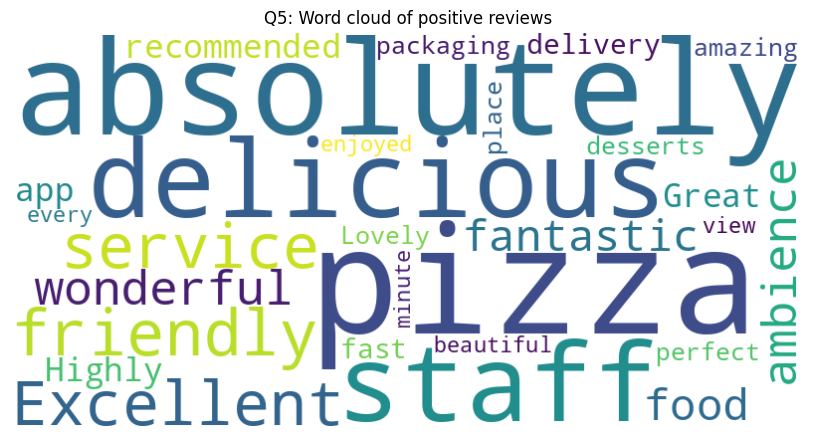

Word cloud saved to q5_wordcloud.png



In [7]:
print("=" * 70, "\nQ5. SENTIMENT ANALYSIS + WORD CLOUD\n", "=" * 70, sep="")
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "The pizza was absolutely delicious and the staff were very friendly.",
    "Excellent service, wonderful ambience and fantastic food. Highly recommended!",
    "Great app, the delivery was fast and the packaging was perfect.",
    "The food was cold and the service was terrible.",
    "Very disappointing, the waiter was rude and the bill was wrong.",
    "Worst delivery ever, the order was late and the burger was awful.",
    "I ordered a sandwich and a coffee on Tuesday evening.",
    "Lovely place with amazing desserts and a beautiful view, we enjoyed every minute.",
]
rows = []
for r in reviews:
    pol, sub = TextBlob(r).sentiment
    label = "Positive" if pol > 0.1 else ("Negative" if pol < -0.1 else "Neutral")
    rows.append((r, round(pol, 3), round(sub, 3), label))
df = pd.DataFrame(rows, columns=["Review", "Polarity", "Subjectivity", "Sentiment"])
pd.set_option("display.max_colwidth", 60, "display.width", 200)
print(df.to_string(index=False), "\n")
print(df["Sentiment"].value_counts().to_string(), "\n")

pos_text = " ".join(df.loc[df.Sentiment == "Positive", "Review"])
wc = WordCloud(width=800, height=400, background_color="white",
               stopwords=set(stopwords.words("english"))).generate(pos_text)
plt.figure(figsize=(9, 4.5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Q5: Word cloud of positive reviews")
plt.tight_layout()
plt.savefig("q5_wordcloud.png", dpi=120)
plt.show()
print("Word cloud saved to q5_wordcloud.png\n")

## Q6. Text generation with LSTM

In [8]:
print("=" * 70, "\nQ6. TEXT GENERATION WITH LSTM\n", "=" * 70, sep="")
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

corpus = (
    "street food is loved by people in every city of india. "
    "vendors cook fresh snacks on hot pans and serve them quickly. "
    "the smell of spices fills the evening air near the market. "
    "people gather around the stalls with their friends and family. "
    "a plate of chaat costs very little but tastes wonderful. "
    "every region has its own special dish and its own special flavour. "
    "good food brings people together and makes every evening happier. "
    "i always return to my favourite stall because the taste reminds me of home."
)
lines = [s.strip() for s in corpus.split(".") if s.strip()]

tok = Tokenizer()
tok.fit_on_texts(lines)
vocab = len(tok.word_index) + 1
print("1) Vocabulary size:", vocab)

seqs = []
for line in lines:
    ids = tok.texts_to_sequences([line])[0]
    for i in range(1, len(ids)):
        seqs.append(ids[: i + 1])
max_len = max(len(s) for s in seqs)
seqs = pad_sequences(seqs, maxlen=max_len, padding="pre")
X, y = seqs[:, :-1], seqs[:, -1]
y = to_categorical(y, num_classes=vocab)
print("2) Input sequences:", X.shape, " Labels:", y.shape)

import tensorflow as tf
tf.random.set_seed(42)
model = Sequential([
    Embedding(vocab, 32),
    LSTM(100),
    Dense(vocab, activation="softmax"),
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, max_len - 1))
model.summary()
hist = model.fit(X, y, epochs=300, verbose=0)
print(f"3) Final training accuracy: {hist.history['accuracy'][-1]:.3f}, "
      f"loss: {hist.history['loss'][-1]:.3f}")

def generate(seed, n_words=8):
    text = seed
    for _ in range(n_words):
        ids = tok.texts_to_sequences([text])[0]
        ids = pad_sequences([ids], maxlen=max_len - 1, padding="pre")
        pred = np.argmax(model.predict(ids, verbose=0), axis=-1)[0]
        word = tok.index_word.get(pred, "")
        if not word:
            break
        text += " " + word
    return text

print("\nGenerated text:")
for seed in ["street", "good", "every"]:
    print(f"   seed '{seed}': {generate(seed)}")

Q6. TEXT GENERATION WITH LSTM
1) Vocabulary size: 71
2) Input sequences: (81, 13)  Labels: (81, 71)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 13, 32)         │         2,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100)            │        53,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 71)             │         7,171 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,643 (244.70 KB)

 Trainable params: 62,643 (244.70 KB)

 Non-trainable params: 0 (0.00 B)

3) Final training accuracy: 1.000, loss: 0.156

Generated text:
   seed 'street': street food is loved by people in every city
   seed 'good': good food brings people together and makes every evening
   seed 'every': every region has its own special dish and its
